## 0. Load and clean

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style='whitegrid')

df = pd.read_excel('second_cleaned_data_power.xlsx')
print('Raw shape:', df.shape)

df = df[df['Quantity'] > 0].copy()          # removes 150 zero-sale rows
print('After removing zero-quantity rows:', df.shape)

df['Order_Month'] = df['Order_Date'].dt.to_period('M').astype(str)   # '2024-01'
df['Month_Num'] = df['Order_Date'].dt.month                          # 1 to 12

df.head()

Raw shape: (50000, 15)
After removing zero-quantity rows: (49850, 15)


,Order_ID,Order_Date,Customer_ID,Product_Category,Fabric,Aesthetic_Style,Color_Palette,Preferred_Cafe_Style,Quantity,Unit_Price,Discount_Percent,Total_Sales,Profit,City,Payment_Method,Order_Month,Month_Num
150,ORD-125467,2024-12-11 10:36:00,CUST-2710,Accessories,Unknown,Urban Monochrome,Monochrome Slate,Unspecified,3,28.79,0.20,69.10,31.10,Phoenix,Klarna,2024-12,12
151,ORD-129174,2024-08-26 14:18:00,CUST-9349,Tops,Corduroy,Vintage Academic,Warm Brown & Cream,Vintage Antique Shop Cafe,4,50.76,0.20,162.43,73.09,Austin,PayPal,2024-08,8
152,ORD-131658,2024-07-22 13:20:00,CUST-5671,Tops,Heavy Cotton,Urban Monochrome,Monochrome Slate,Minimalist Espresso Bar,4,217.51,0.05,826.54,371.94,New York,PayPal,2024-07,7
153,ORD-143874,2024-06-20 20:22:00,CUST-3542,Tops,Tweed,Vintage Academic,Forest Green & Mustard,Cozy Wooden Library,3,148.13,0.20,355.51,159.98,Phoenix,PayPal,2024-06,6
154,ORD-126037,2024-01-24 07:15:00,CUST-5582,Outerwear,Light Cotton,Coastal Minimalist,Sage Green & Beige,Sunlit Open Patio,1,146.21,0.15,124.28,55.93,Los Angeles,Apple Pay,2024-01,1


In [ ]:
print("\n=== LAST 5 ROWS (TAIL) ===")
print(df.tail())


=== LAST 5 ROWS (TAIL) ===
         Order_ID          Order_Date Customer_ID Product_Category  \
49995  ORD-111285 2024-06-24 10:07:00   CUST-7084             Tops   
49996  ORD-144733 2024-11-24 10:33:00   CUST-7178          Bottoms   
49997  ORD-138159 2024-01-31 11:58:00   CUST-4690        Outerwear   
49998  ORD-100861 2024-10-21 20:12:00   CUST-5542        Outerwear   
49999  ORD-115796 2024-02-08 08:44:00   CUST-7117             Tops   

             Fabric     Aesthetic_Style           Color_Palette  \
49995          Silk  Coastal Minimalist       Ocean Blue & Sand   
49996          Wool    Vintage Academic  Forest Green & Mustard   
49997  Light Cotton  Coastal Minimalist      Sage Green & Beige   
49998         Nylon  Streetwear Utility      Neon Green & Black   
49999         Nylon  Streetwear Utility      Earth Khaki & Camo   

              Preferred_Cafe_Style  Quantity  Unit_Price  Discount_Percent  \
49995            Sunlit Open Patio         1      226.03              

In [ ]:
print("\n=== DATASET SUMMARY (INFO) ===")
df.info()


=== DATASET SUMMARY (INFO) ===
<class 'pandas.core.frame.DataFrame'>
Index: 49850 entries, 150 to 49999
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Order_ID              49850 non-null  object        
 1   Order_Date            49850 non-null  datetime64[ns]
 2   Customer_ID           49850 non-null  object        
 3   Product_Category      49850 non-null  object        
 4   Fabric                49850 non-null  object        
 5   Aesthetic_Style       49850 non-null  object        
 6   Color_Palette         49850 non-null  object        
 7   Preferred_Cafe_Style  49850 non-null  object        
 8   Quantity              49850 non-null  int64         
 9   Unit_Price            49850 non-null  float64       
 10  Discount_Percent      49850 non-null  float64       
 11  Total_Sales           49850 non-null  float64       
 12  Profit                49850 non-null  float64

In [ ]:
print("\n=== NULL VALUE COUNT ===")
print(df.isnull().sum())

print("\n=== DUPLICATE COUNT ===")
print(f"Total Duplicates: {df.duplicated().sum()}")


=== NULL VALUE COUNT ===
Order_ID                0
Order_Date              0
Customer_ID             0
Product_Category        0
Fabric                  0
Aesthetic_Style         0
Color_Palette           0
Preferred_Cafe_Style    0
Quantity                0
Unit_Price              0
Discount_Percent        0
Total_Sales             0
Profit                  0
City                    0
Payment_Method          0
Order_Month             0
Month_Num               0
dtype: int64

=== DUPLICATE COUNT ===
Total Duplicates: 0


In [ ]:
print("\n=== NUMERICAL DESCRIPTIVE STATISTICS ===")
print(df.describe().round(2))


=== NUMERICAL DESCRIPTIVE STATISTICS ===
                          Order_Date  Quantity  Unit_Price  Discount_Percent  \
count                          49850  49850.00    49850.00          49850.00   
mean   2024-07-01 14:08:48.022868224      2.51      137.22              0.10   
min              2024-01-01 00:00:00      1.00       25.00              0.00   
25%              2024-03-31 23:23:30      2.00       80.93              0.05   
50%              2024-07-01 10:06:00      3.00      137.12              0.10   
75%              2024-10-01 04:40:15      4.00      193.53              0.15   
max              2024-12-31 23:58:00      4.00      250.00              0.20   
std                              NaN      1.12       65.00              0.07   

       Total_Sales    Profit  Month_Num  
count     49850.00  49850.00   49850.00  
mean        309.49    139.27       6.50  
min          20.01      9.00       1.00  
25%         139.92     62.96       3.00  
50%         247.46    111.3

In [ ]:
print("\n=== VALUE COUNTS (CATEGORICAL) ===")
print("Product Category Distribution:\n", df["Product_Category"].value_counts())
print("\nAesthetic Style Distribution:\n", df["Aesthetic_Style"].value_counts())


=== VALUE COUNTS (CATEGORICAL) ===
Product Category Distribution:
 Product_Category
Outerwear      8409
Knitwear       8395
Accessories    8298
Bottoms        8293
Tops           8260
Footwear       8195
Name: count, dtype: int64

Aesthetic Style Distribution:
 Aesthetic_Style
Coastal Minimalist    12557
Vintage Academic      12470
Streetwear Utility    12428
Urban Monochrome      12395
Name: count, dtype: int64


In [ ]:
# 5. GroupBy & Aggregation Metrics
category_summary = df.groupby("Product_Category").agg({
    "Total_Sales": ["sum", "mean", "max"],
    "Profit": ["sum", "mean"],
    "Quantity": "sum"
}).round(2)

Things to know about this file:
- `Discount_Percent` is a fraction (0.10 = 10%).
- `City` and `Fabric` each have about 1,500 'Unknown' rows. Filter them when ranking.
- `Profit` is exactly 45% of `Total_Sales` in every row (a quirk of this dataset).

In [ ]:
# Quick data quality check
print(df.isna().sum().sum(), 'missing values')
print((df['City'] == 'Unknown').sum(), 'Unknown cities')
print((df['Fabric'] == 'Unknown').sum(), 'Unknown fabrics')
print((df['Profit'] / df['Total_Sales']).round(3).unique()[:5], '<- profit margin')

0 missing values
1499 Unknown cities
1478 Unknown fabrics
[0.45] <- profit margin


---
# PART 1: WHAT happened?
## Chart 1: Line Chart
**Question:** How is something changing over time?  
**Data:** Date/ordered on X, numeric on Y. **Use for:** monthly sales, revenue and profit trends.  
**Do not use for:** unordered categories, only 2 to 3 time points, more than about 5 lines.

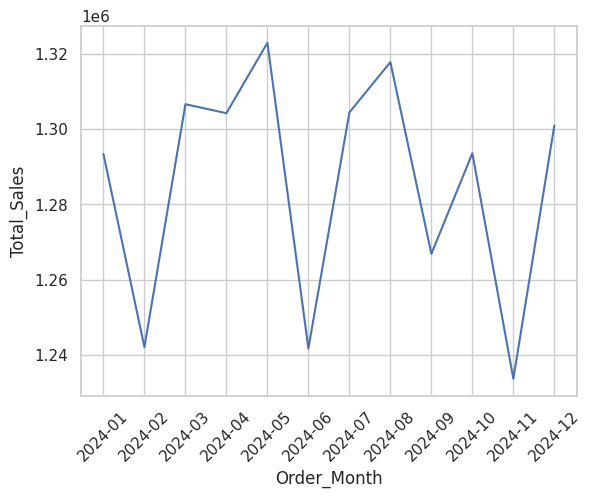

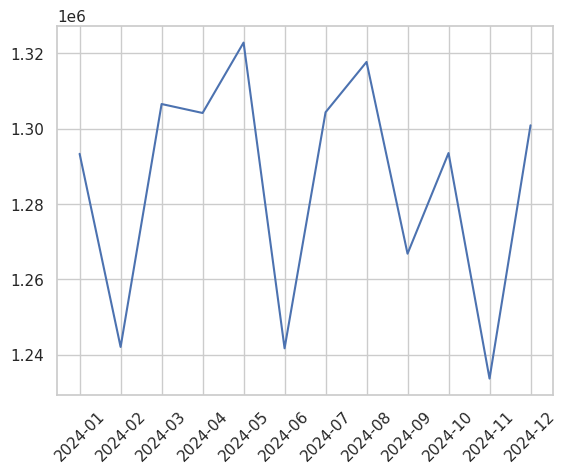

In [ ]:
# Simple
monthly = df.groupby('Order_Month')['Total_Sales'].sum().reset_index()

sns.lineplot(data=monthly, x='Order_Month', y='Total_Sales')
plt.xticks(rotation=45)
plt.show()

# Matplotlib version
plt.plot(monthly['Order_Month'], monthly['Total_Sales'])
plt.xticks(rotation=45)
plt.show()

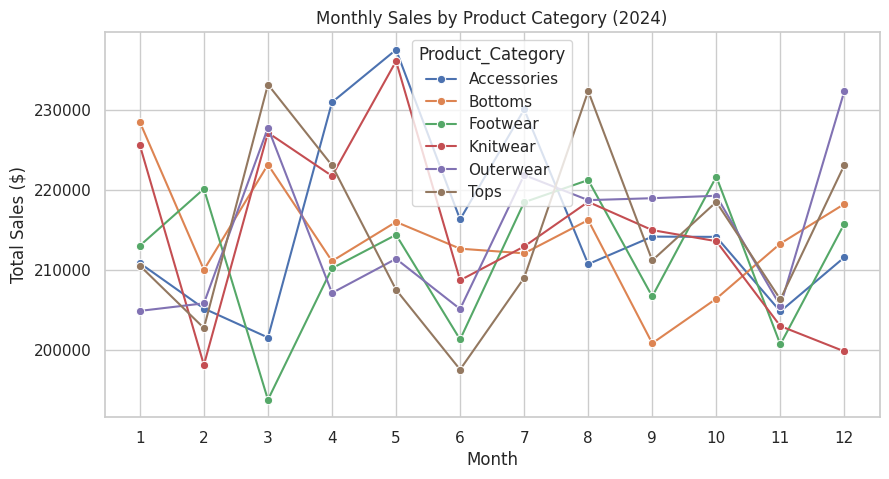

In [ ]:
# Medium: one line per product category
monthly_cat = (df.groupby(['Month_Num', 'Product_Category'])['Total_Sales']
                 .sum()
                 .reset_index())

plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly_cat, x='Month_Num', y='Total_Sales',
             hue='Product_Category', marker='o')
plt.title('Monthly Sales by Product Category (2024)')
plt.xlabel('Month')
plt.ylabel('Total Sales ($)')
plt.xticks(range(1, 13))
plt.show()

## Chart 2: Bar Chart
**Question:** Which category performs better?  
**Data:** categorical X, numeric Y. **Use for:** revenue by category, profit by region, average sales by segment.  
**Do not use for:** many categories or long names (use horizontal bar), trends over time, Y-axis not starting at zero.

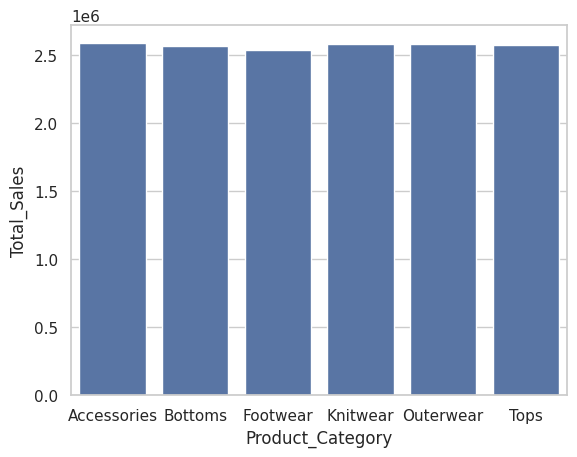

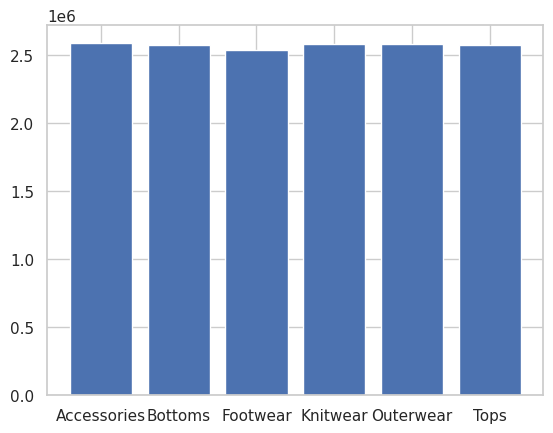

In [ ]:
# Simple: total sales by category
cat_sales = df.groupby('Product_Category')['Total_Sales'].sum().reset_index()

sns.barplot(data=cat_sales, x='Product_Category', y='Total_Sales')
plt.show()

# Matplotlib version
plt.bar(cat_sales['Product_Category'], cat_sales['Total_Sales'])
plt.show()

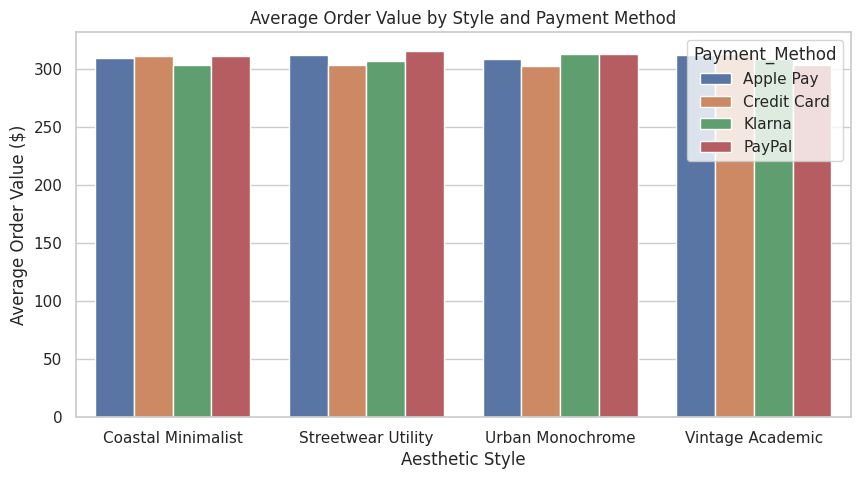

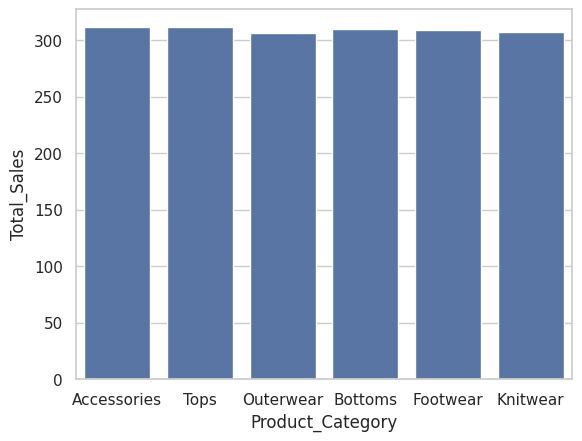

In [ ]:
# Medium: average order value by style and payment method
avg_sales = (df.groupby(['Aesthetic_Style', 'Payment_Method'])['Total_Sales']
               .mean()
               .reset_index())

plt.figure(figsize=(10, 5))
sns.barplot(data=avg_sales, x='Aesthetic_Style', y='Total_Sales', hue='Payment_Method')
plt.title('Average Order Value by Style and Payment Method')
plt.xlabel('Aesthetic Style')
plt.ylabel('Average Order Value ($)')
plt.show()

# Note: on the raw df, sns.barplot plots the AVERAGE, not the sum
sns.barplot(data=df, x='Product_Category', y='Total_Sales', errorbar=None)
plt.show()

## Chart 3: Horizontal Bar Chart
**Question:** What are the top and bottom performers?  
**Data:** categorical names + numeric value, sorted. **Use for:** rankings, top/bottom 10, long labels.  
**Memory trick:** after `sort_values()` (ascending), `.tail()` = top, `.head()` = bottom.

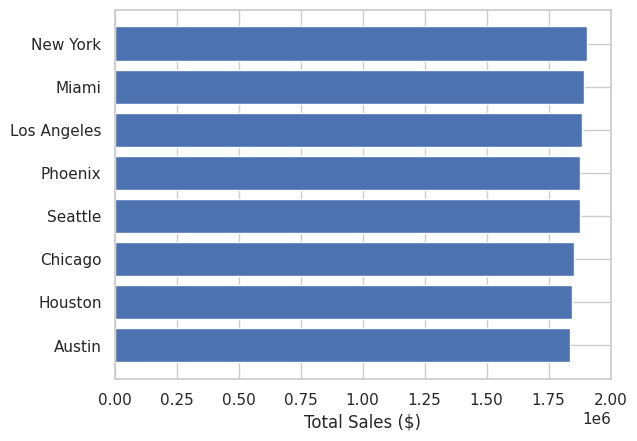

In [ ]:
# Simple: city ranking (Unknown removed)
city_sales = (df[df['City'] != 'Unknown']
                .groupby('City')['Total_Sales']
                .sum()
                .sort_values())

plt.barh(city_sales.index, city_sales.values)
plt.xlabel('Total Sales ($)')
plt.show()

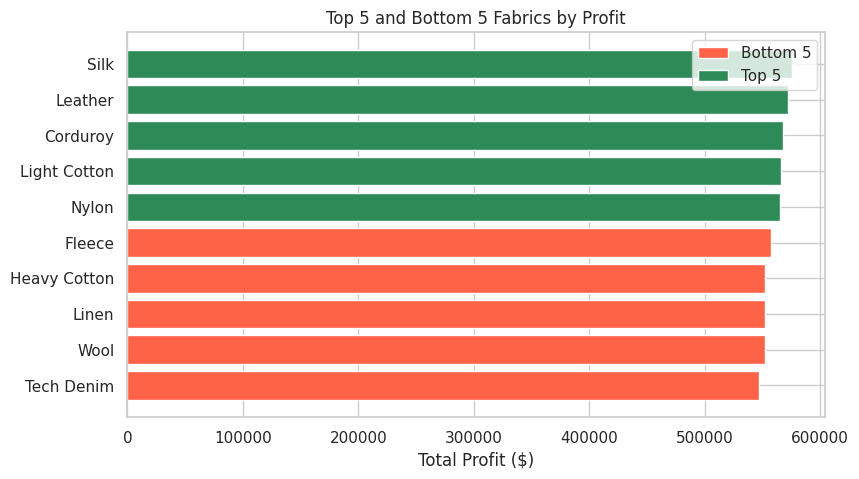

In [ ]:
# Medium: top 5 and bottom 5 fabrics by profit
fabric_profit = (df[df['Fabric'] != 'Unknown']
                   .groupby('Fabric')['Profit']
                   .sum()
                   .sort_values())

top5 = fabric_profit.tail(5)
bottom5 = fabric_profit.head(5)

plt.figure(figsize=(9, 5))
plt.barh(bottom5.index, bottom5.values, color='tomato', label='Bottom 5')
plt.barh(top5.index, top5.values, color='seagreen', label='Top 5')
plt.title('Top 5 and Bottom 5 Fabrics by Profit')
plt.xlabel('Total Profit ($)')
plt.legend()
plt.show()

**Story:** New York led city revenue at $1.90M and Austin ranked last at $1.83M, a gap of only 3.9%. Performance is consistent across all eight cities, so the priority is lifting the whole network rather than rescuing a weak market.  
**Mistakes:** not sorting, mixing up `.head()` and `.tail()`, leaving 'Unknown' in the ranking, showing too many bars.  
**Interview:** Top 5 products by sales? `groupby().sum().sort_values(ascending=False).head(5)` then `plt.barh()`.

---
# PART 2: WHY is it happening?
## Chart 4: Histogram
**Question:** How are the values distributed?  
**Data:** one numeric column. **Use for:** order value, age, salary, delivery time.  
**Key ideas:** `bins` = number of ranges (try 20 to 40); right-skewed = long tail of big values, mean above median.

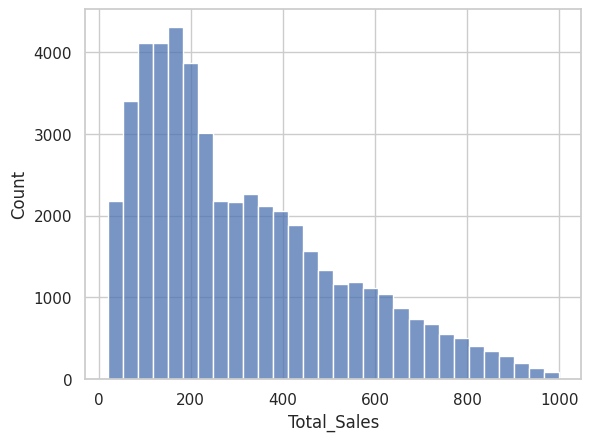

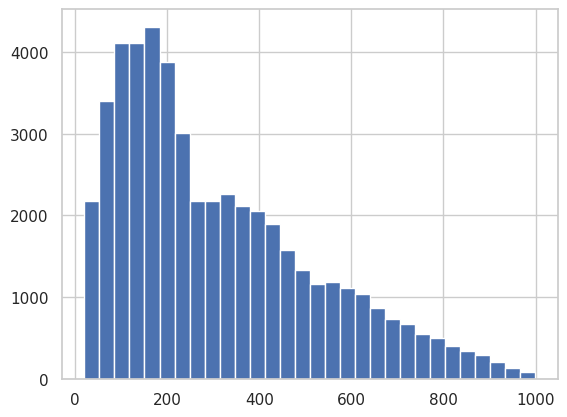

In [ ]:
# Simple
sns.histplot(data=df, x='Total_Sales', bins=30)
plt.show()

# Matplotlib version
plt.hist(df['Total_Sales'], bins=30)
plt.show()

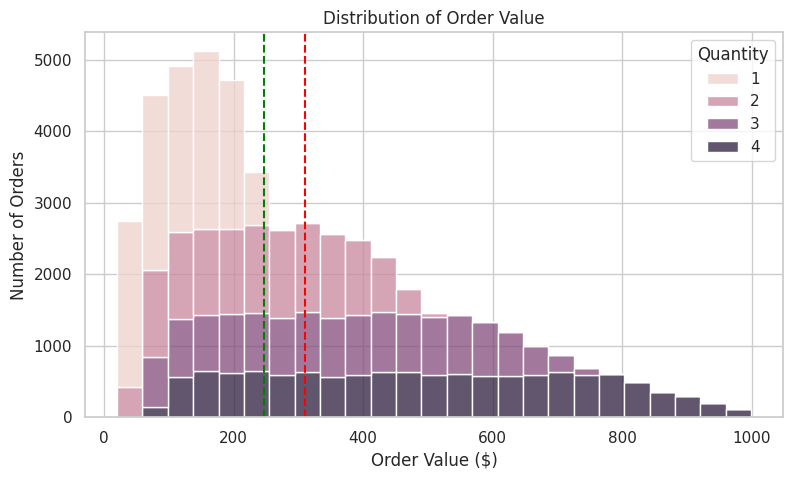

Mean: 309.5
Median: 247.5


In [ ]:
# Medium: stacked by quantity, with mean and median lines
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x='Total_Sales', bins=25, hue='Quantity', multiple='stack')

plt.axvline(df['Total_Sales'].mean(), color='red', linestyle='--')      # mean
plt.axvline(df['Total_Sales'].median(), color='green', linestyle='--')  # median

plt.title('Distribution of Order Value')
plt.xlabel('Order Value ($)')
plt.ylabel('Number of Orders')
plt.show()

print('Mean:', round(df['Total_Sales'].mean(), 1))
print('Median:', round(df['Total_Sales'].median(), 1))

## Chart 5: Box Plot
**Question:** Are there unusual values, and how do groups differ?  
**Read it:** line in the box = **median**; box edges = **Q1** and **Q3**; box height = **IQR** (Q3 - Q1, the middle 50%); whiskers reach 1.5 x IQR; dots beyond = **outliers**.

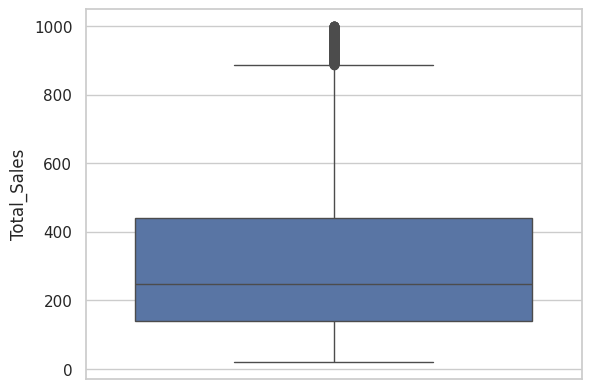

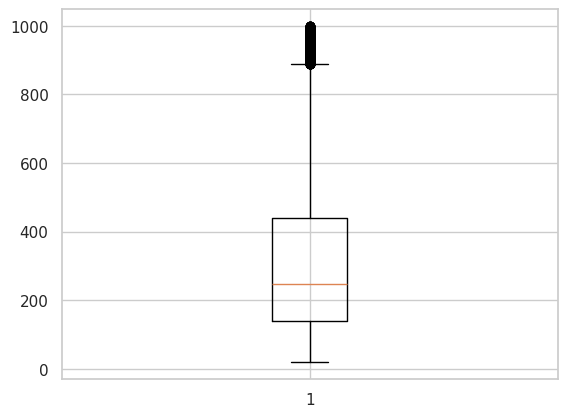

In [ ]:
# Simple
sns.boxplot(data=df, y='Total_Sales')
plt.show()

# Matplotlib version
plt.boxplot(df['Total_Sales'])
plt.show()

534 orders above 888
Quantity
4    534
Name: count, dtype: int64


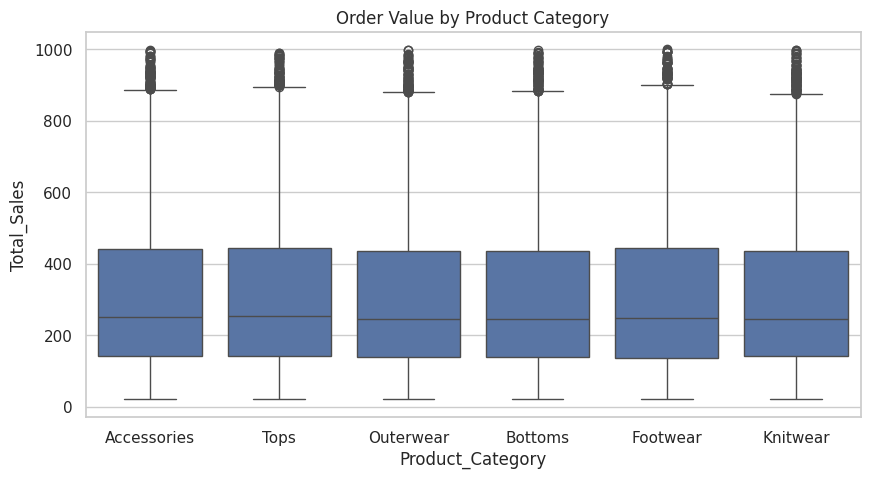

In [ ]:
# Medium: count outliers with the IQR rule, then compare categories
q1 = df['Total_Sales'].quantile(0.25)
q3 = df['Total_Sales'].quantile(0.75)
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr

outliers = df[df['Total_Sales'] > upper_fence]
print(len(outliers), 'orders above', round(upper_fence))
print(outliers['Quantity'].value_counts())

plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='Product_Category', y='Total_Sales')
plt.title('Order Value by Product Category')
plt.show()

## Chart 6: Scatter Plot
**Question:** Are two numeric variables related?  
**Data:** numeric vs numeric. **Patterns:** positive, negative, no relationship, outliers, bands from discrete variables.  
Use a random sample (`df.sample`) so 50,000 dots do not become a blob.

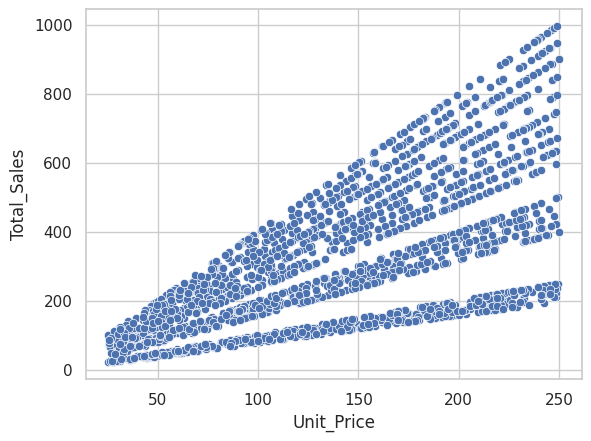

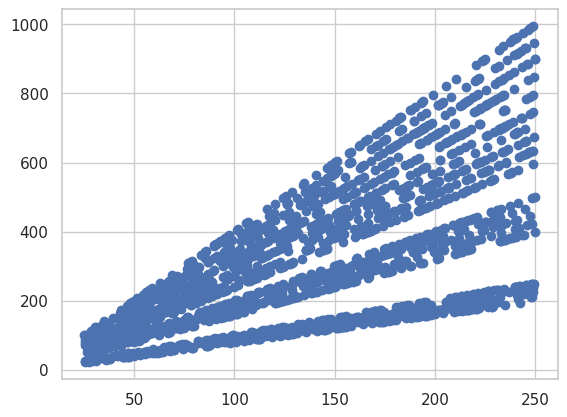

In [ ]:
# Simple
sample = df.sample(2000, random_state=1)

sns.scatterplot(data=sample, x='Unit_Price', y='Total_Sales')
plt.show()

# Matplotlib version
plt.scatter(sample['Unit_Price'], sample['Total_Sales'])
plt.show()

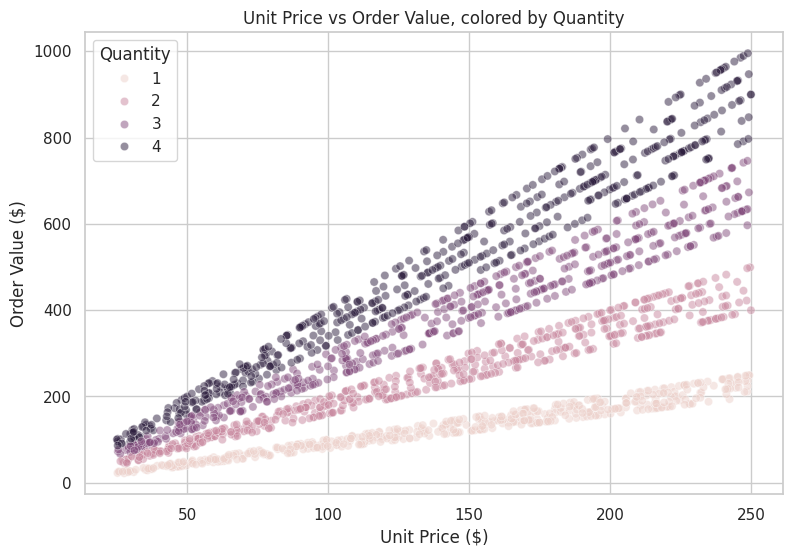

Price vs Sales correlation: 0.69
Price vs Quantity correlation: 0.0


In [ ]:
# Medium: color by quantity and put a number on the pattern
plt.figure(figsize=(9, 6))
sns.scatterplot(data=sample, x='Unit_Price', y='Total_Sales', hue='Quantity', alpha=0.5)
plt.title('Unit Price vs Order Value, colored by Quantity')
plt.xlabel('Unit Price ($)')
plt.ylabel('Order Value ($)')
plt.show()

print('Price vs Sales correlation:', round(df['Unit_Price'].corr(df['Total_Sales']), 2))
print('Price vs Quantity correlation:', round(df['Unit_Price'].corr(df['Quantity']), 2))

## Chart 8: Heatmap
**Question:** Which numeric variables are strongly related?  
**Rough guide:** under 0.3 weak, 0.3 to 0.7 moderate, above 0.7 strong. Diagonal is always 1.00. **Correlation does not prove causation.**

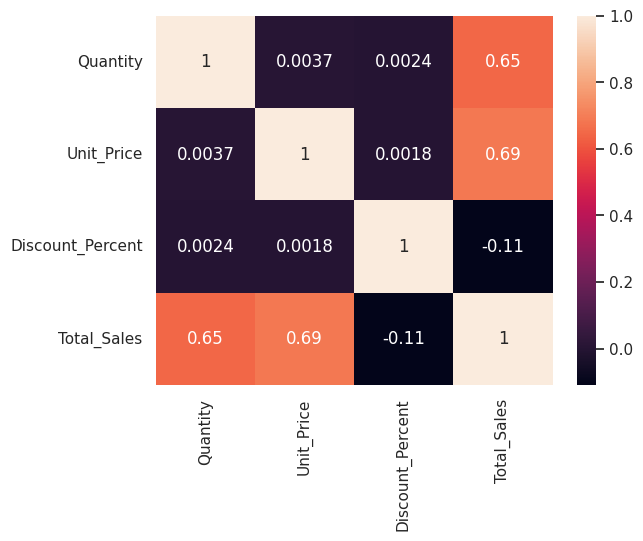

In [ ]:
# Simple
corr = df[['Quantity', 'Unit_Price', 'Discount_Percent', 'Total_Sales']].corr()

sns.heatmap(corr, annot=True)
plt.show()

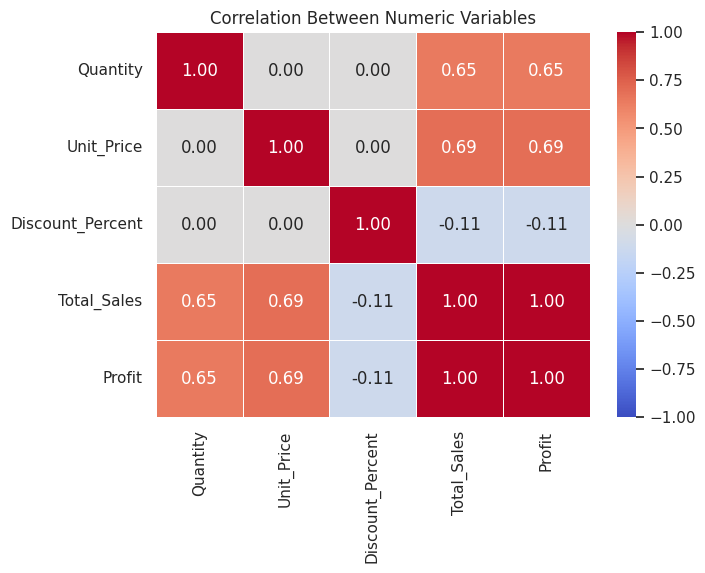

In [ ]:
# Medium
cols = ['Quantity', 'Unit_Price', 'Discount_Percent', 'Total_Sales', 'Profit']
corr = df[cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Between Numeric Variables')
plt.show()

---
# PART 3: What should we do?
## Chart 9: Count Plot
**Question:** How many observations belong to each category?  
**Data:** one categorical column (no Y needed). Also a quick data-quality check.

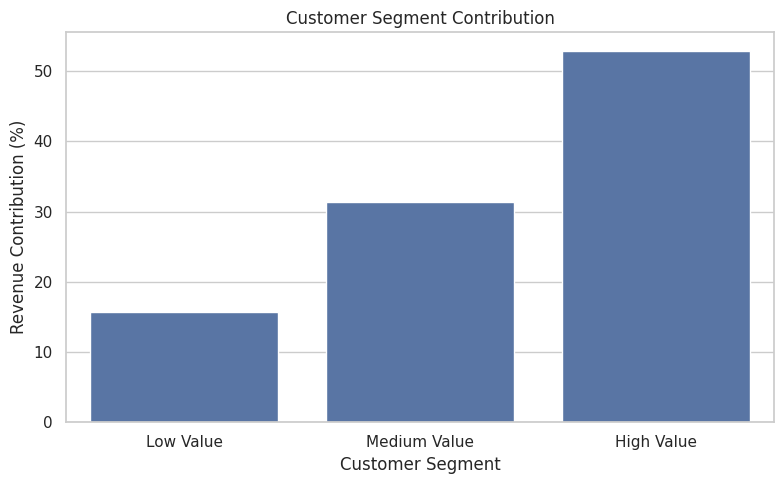

Segment
Low Value       15.76
Medium Value    31.34
High Value      52.90
Name: Total_Sales, dtype: float64


In [ ]:
# Customer Segment Contribution

customer_sales = df.groupby("Customer_ID")["Total_Sales"].sum()

customer_sales = customer_sales.sort_values(ascending=False)

customer_sales = customer_sales.reset_index()
customer_sales.columns = ["Customer_ID", "Total_Sales"]

customer_sales["Segment"] = pd.qcut(
    customer_sales["Total_Sales"].rank(method="first"),
    3,
    labels=["Low Value", "Medium Value", "High Value"]
)

segment_sales = customer_sales.groupby(
    "Segment", observed=False
)["Total_Sales"].sum()

segment_share = segment_sales / segment_sales.sum() * 100

plt.figure(figsize=(8, 5))

sns.barplot(
    x=segment_share.index,
    y=segment_share.values
)

plt.title("Customer Segment Contribution")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue Contribution (%)")

plt.tight_layout()
plt.show()

print(segment_share.round(2))

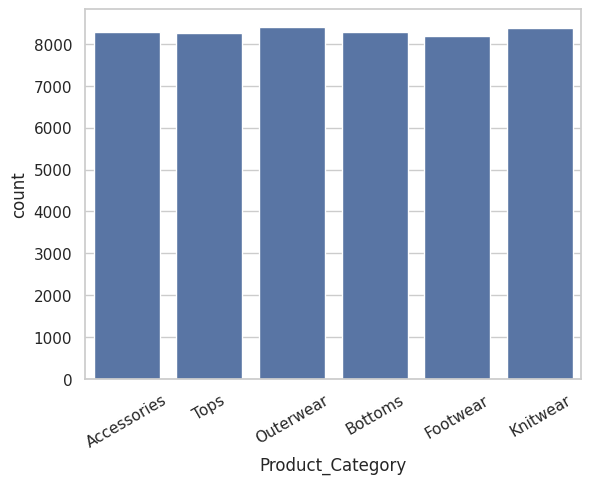

In [ ]:
# Simple
sns.countplot(data=df, x='Product_Category')
plt.xticks(rotation=30)
plt.show()

In [ ]:
# Medium: add hue, then a sorted horizontal version
sns.countplot(data=df, x='Product_Category', hue='Payment_Method')
plt.xticks(rotation=30)
plt.show()

city_order = df['City'].value_counts().index

plt.figure(figsize=(8, 5))
sns.countplot(data=df, y='City', order=city_order)
plt.title('Orders by City')
plt.xlabel('Number of Orders')
plt.show()

---
# Final comparison table
| Chart | Main purpose | X data | Y data | Best use |
|---|---|---|---|---|
| Line | Trend | Date/ordered | Numeric | Time analysis |
| Bar | Comparison | Categorical | Numeric | Category comparison |
| Horizontal Bar | Ranking | Categorical | Numeric | Top/bottom |
| Histogram | Distribution | Numeric | Frequency | Distribution |
| Box Plot | Spread/outliers | Category/Numeric | Numeric | Outlier analysis |
| Scatter | Relationship | Numeric | Numeric | Relationship |
| Regression | Relationship + trend | Numeric | Numeric | Trend/association |
| Heatmap | Correlation | Numeric variables | Numeric variables | Correlation analysis |
| Count Plot | Frequency | Categorical | Count | Category frequency |

# Final story: Observation, Evidence, Business meaning, Recommendation

In [ ]:
# Numbers behind the final story
print('Orders:', len(df), '| Customers:', df['Customer_ID'].nunique())

cust = df.groupby('Customer_ID')['Total_Sales'].sum().sort_values(ascending=False)
top10 = cust.head(int(len(cust) * 0.10)).sum() / cust.sum()
print('Top 10% of customers share of revenue:', round(top10 * 100, 1), '%')

print('Monthly sales range:', round(monthly['Total_Sales'].min()), 'to', round(monthly['Total_Sales'].max()))
print('Median order:', round(df['Total_Sales'].median()), '| Mean order:', round(df['Total_Sales'].mean()))

Orders: 49850 | Customers: 8969
Top 10% of customers share of revenue: 20.2 %
Monthly sales range: 1233697 to 1322880
Median order: 247 | Mean order: 309
